CI2 — GRU baseline: results, qualitative examples, failure analysis

This notebook **does not run inference**. It loads `runs/gru_h64/test_preds.npz` written by `python -m src.evaluate` (GRU, persistence and historical-average predictions on the same 6,832 test windows) and produces every number and figure in [`check-in-2.md`](../check-in-2.md). Figures go to `figures/`, and the quoted numbers are also dumped to `figures/ci2_numbers.json`.

Data is read from `DATA_DIR` (default `../Project_check_in_1/data`; to use another location, pass `data_paths("/path/to/data")`).

In [14]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.config import data_paths, FIG_DIR, RUNS_DIR
from src.data import load_processed, load_adj, load_locations
from src.evaluate import results_table

warnings.filterwarnings("ignore", "Mean of empty slice")
RUN = "gru_h64"
P = data_paths()
arrays, meta = load_processed(P["processed"])
_, _, ADJ = load_adj(P["adj"], sensor_ids=meta["sensor_ids"])
LOC = load_locations(P["locations"])
run = RUNS_DIR / RUN
with np.load(run / "test_preds.npz") as z:
    y = z["y"]
    PRED = {"GRU": z["gru"], "Persistence": z["persistence"], "HA": z["ha"]}
    TGT, XMISS = z["target_index"], z["x_missing_frac"]
TS = pd.DatetimeIndex(pd.to_datetime(arrays["timestamps"]))
RAW, SIDS = arrays["raw"], np.array(meta["sensor_ids"])
s_te, e_te = meta["splits"]["test"]
OBS = y != 0
ERR = {k: np.abs(p - y) for k, p in PRED.items()}
MODELS = list(PRED)
NUM = {}   # every number quoted in check-in-2.md
print(f"DATA_DIR = {P['data_dir']}")
print(f"test windows {y.shape[0]:,} x horizons {y.shape[1]} x sensors {y.shape[2]}; observed targets {OBS.mean():.1%}")

FIG = FIG_DIR; FIG.mkdir(exist_ok=True)
C1, C2, C3, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
COL = {"GRU": C1, "Persistence": C2, "HA": C3, "truth": "#222222"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False,
                     "lines.linewidth": 1.5})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show()

def mae(k, sel):
    """Masked MAE of model k over boolean selection sel (same shape as y); zeros excluded."""
    sel = sel & OBS
    return float(ERR[k][sel].mean())

DATA_DIR = /Users/mikekwon/Documents/georgetownFall26/DSAN6600/Deep-Learning-6600/Project_check_in_1/data
test windows 6,832 x horizons 12 x sensors 207; observed targets 87.9%


## 1. Training run
Resolved config, run summary and learning curve (from `runs/gru_h64/`).

,value
hidden,64
layers,2
dropout,0.1
head_hidden,128
use_mask,True
lr,0.001
weight_decay,0.0001
batch_size,64
clip,5.0
lr_factor,0.5


,value
epochs_trained,40
best_epoch,40
best_val_mae,3.249127
wall_clock_min,18.217497
n_params,51340
device,mps


mean epoch time 27.3s; final lr 2.5e-04


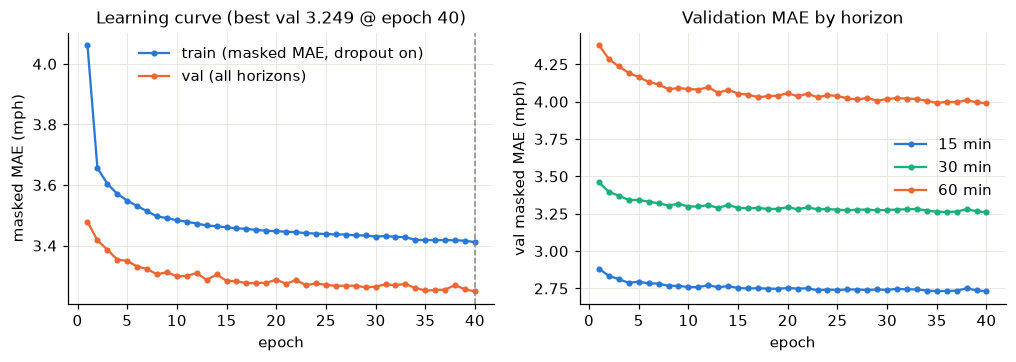

In [15]:
cfg = json.loads((run / "config.json").read_text())
summ = json.loads((run / "summary.json").read_text())
hist = pd.read_csv(run / "metrics.csv")
keys = ["hidden", "layers", "dropout", "head_hidden", "use_mask", "lr", "weight_decay", "batch_size",
        "clip", "lr_factor", "lr_patience", "es_patience", "max_epochs", "seed", "device"]
display(pd.DataFrame({"value": {k: cfg[k] for k in keys}}))
display(pd.DataFrame({"value": summ}))
NUM["training"] = {**summ, "mean_epoch_sec": float(hist.epoch_sec.mean()),
                   "lr_final": float(hist.lr.iloc[-1]), "lr_reductions": int((hist.lr.diff() < 0).sum())}
print(f"mean epoch time {hist.epoch_sec.mean():.1f}s; final lr {hist.lr.iloc[-1]:.1e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(hist.epoch, hist.train_loss, "o-", ms=3, color=C1, label="train (masked MAE, dropout on)")
ax[0].plot(hist.epoch, hist.val_mae, "o-", ms=3, color=C2, label="val (all horizons)")
ax[0].axvline(summ["best_epoch"], color=GRAY, ls="--", lw=1)
ax[0].set(xlabel="epoch", ylabel="masked MAE (mph)", title=f"Learning curve (best val {summ['best_val_mae']:.3f} @ epoch {summ['best_epoch']})")
ax[0].legend()
for c, col, lab in [("val_mae_15", C1, "15 min"), ("val_mae_30", C3, "30 min"), ("val_mae_60", C2, "60 min")]:
    ax[1].plot(hist.epoch, hist[c], "o-", ms=3, color=col, label=lab)
ax[1].set(xlabel="epoch", ylabel="val masked MAE (mph)", title="Validation MAE by horizon"); ax[1].legend()
save(fig, "R0_learning_curve")

## 2. Test results (masked MAE / RMSE / MAPE at 15 / 30 / 60 min)
Persistence and HA are recomputed on the *same* windows by `src/evaluate.py`, which asserts they match CI1's `figures/probe_results.csv`.

In [16]:
res = results_table({"gru": PRED["GRU"], "persistence": PRED["Persistence"], "ha": PRED["HA"]}, y)
display(res.round(2))
saved = pd.read_csv(FIG / "results_table.csv", header=[0, 1], index_col=0)
assert np.allclose(saved.values.astype(float), res.round(2).values.astype(float)), "results_table.csv is stale - re-run src.evaluate"
NUM["results"] = {m: {f"{h} {k}": round(float(v), 2) for (h, k), v in r.items()} for m, r in res.iterrows()}
gru = res.iloc[0]
for h in ["15 min", "30 min", "60 min"]:
    base = res.iloc[1:3][(h, "MAE")]
    best_name, best = base.idxmin(), base.min()
    print(f"{h}: GRU MAE {gru[(h, 'MAE')]:.2f} vs best probe {best:.2f} ({best_name.split(' (')[0]}) "
          f"-> {100 * (1 - gru[(h, 'MAE')] / best):.1f}% lower")
    NUM.setdefault("gain_vs_best_probe_pct", {})[h] = round(100 * (1 - gru[(h, 'MAE')] / best), 1)

horizon                               15 min                30 min        \
metric                                   MAE  RMSE MAPE (%)    MAE  RMSE   
model                                                                      
GRU (shared-weight, ours)               2.99  5.89     8.03   3.60  7.28   
Persistence (last observed)             3.71  7.47     8.94   4.62  9.64   
Historical average (dow × tod, train)   4.19  7.86    13.06   4.19  7.86   

horizon                                        60 min                  
metric                                MAPE (%)    MAE   RMSE MAPE (%)  
model                                                                  
GRU (shared-weight, ours)                10.32   4.46   8.95    13.76  
Persistence (last observed)              11.48   6.14  12.61    15.69  
Historical average (dow × tod, train)    13.06   4.19   7.86    13.06

15 min: GRU MAE 2.99 vs best probe 3.71 (Persistence) -> 19.4% lower
30 min: GRU MAE 3.60 vs best probe 4.19 (Historical average) -> 14.2% lower
60 min: GRU MAE 4.46 vs best probe 4.19 (Historical average) -> -6.5% lower


**Takeaway.** The GRU has the lowest MAE of all three models at 15 min (2.99, 19.4% below persistence) and 30 min (3.60, 14.2% below HA). At **60 min it is 6.5% worse than HA (4.46 vs 4.19)**, and its RMSE is also higher (8.95 vs 7.86). HA is a separate lookup per sensor × day-of-week × 5-min slot. The sensor-agnostic GRU (no sensor ID, no day-of-week in this config) cannot recover that profile once the last hour stops being informative.

### MAE vs horizon (5–60 min)

horizon (min),5,10,15,20,25,30,35,40,45,50,55,60
GRU,2.381,2.732,2.994,3.216,3.414,3.599,3.770,3.926,4.072,4.207,4.338,4.465
Persistence,2.887,3.353,3.715,4.036,4.335,4.619,4.893,5.156,5.407,5.656,5.900,6.143
HA,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193,4.193


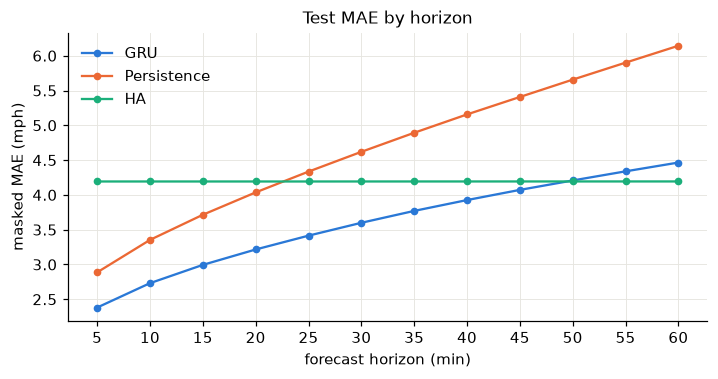

GRU beats persistence at every horizon: True; GRU < HA up to 45 min
GRU MAE grows 2.38 -> 4.46 mph from 5 to 60 min (1.87x)


In [17]:
H = np.arange(1, 13)
def hsel(h):
    s = np.zeros_like(OBS); s[:, h] = True; return s
per_h = pd.DataFrame({k: [mae(k, hsel(h)) for h in range(12)] for k in MODELS}, index=H * 5)
per_h.index.name = "horizon (min)"
display(per_h.round(3).T)
per_h.round(3).to_csv(FIG / "mae_by_horizon.csv")
cross = per_h.index[(per_h.GRU < per_h.HA)].max()
NUM["mae_by_horizon"] = per_h.round(2).to_dict()
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for k in MODELS:
    ax.plot(per_h.index, per_h[k], "o-", ms=4, color=COL[k], label=k)
ax.set(xlabel="forecast horizon (min)", ylabel="masked MAE (mph)", title="Test MAE by horizon", xticks=range(5, 65, 5))
ax.legend()
save(fig, "R1_mae_by_horizon")
print(f"GRU beats persistence at every horizon: {(per_h.GRU < per_h.Persistence).all()}; "
      f"GRU < HA up to {cross} min" if (per_h.GRU < per_h.HA).any() else "GRU never beats HA")
print(f"GRU MAE grows {per_h.GRU.iloc[0]:.2f} -> {per_h.GRU.iloc[-1]:.2f} mph from 5 to 60 min "
      f"({per_h.GRU.iloc[-1] / per_h.GRU.iloc[0]:.2f}x)")

**Takeaway.** The GRU beats persistence at every horizon (2.38 → 4.46 mph from 5 to 60 min, 1.87× growth vs 2.13× for persistence). It crosses HA between 45 min (4.07 < 4.19) and 50 min (4.21).

### Congested (target < 40 mph) vs free-flow (≥ 40 mph)

,horizon,regime,share of targets,GRU,Persistence,HA
0,15 min,congested (<40),0.124,7.448,7.341,12.899
1,15 min,free-flow (>=40),0.876,2.366,3.203,2.964
2,30 min,congested (<40),0.124,10.182,9.674,12.900
3,30 min,free-flow (>=40),0.876,2.670,3.905,2.964
4,60 min,congested (<40),0.124,14.456,13.418,12.905
5,60 min,free-flow (>=40),0.876,3.056,5.117,2.965


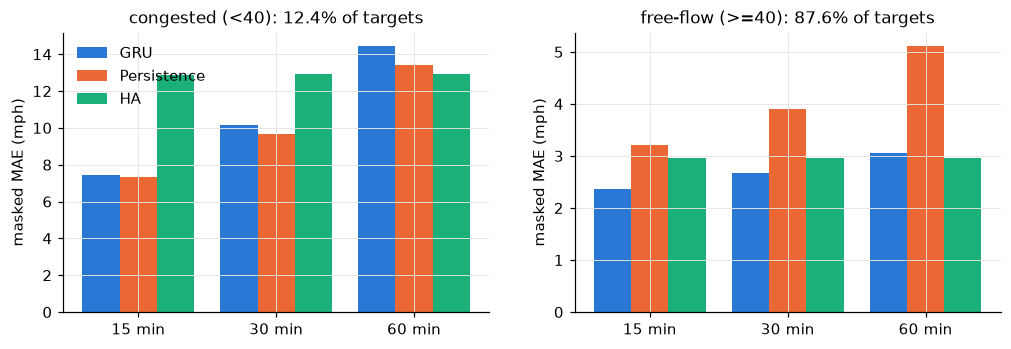

60 min: GRU congested MAE 14.46 vs free-flow 3.06 (4.7x); congested targets are 12.4% of the test set


In [18]:
CONG, FREE = OBS & (y < 40), OBS & (y >= 40)
rows = []
for h in (3, 6, 12):
    for regime, R in [("congested (<40)", CONG), ("free-flow (>=40)", FREE)]:
        sel = np.zeros_like(OBS); sel[:, h - 1] = True; sel &= R
        rows.append({"horizon": f"{h * 5} min", "regime": regime, "share of targets": sel.sum() / (OBS[:, h - 1].sum()),
                     **{k: mae(k, sel) for k in MODELS}})
reg = pd.DataFrame(rows)
display(reg.round(3))
reg.round(3).to_csv(FIG / "mae_congested_vs_free.csv", index=False)
NUM["regime"] = reg.round(2).to_dict("records")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for ax, regime in zip(axs, reg.regime.unique()):
    d = reg[reg.regime == regime].set_index("horizon")[MODELS]
    xs = np.arange(len(d))
    for i, k in enumerate(MODELS):
        ax.bar(xs + (i - 1) * 0.27, d[k], 0.27, color=COL[k], label=k)
    ax.set(xticks=xs, xticklabels=d.index, ylabel="masked MAE (mph)",
           title=f"{regime}: {reg[reg.regime == regime]['share of targets'].iloc[0]:.1%} of targets")
axs[0].legend()
save(fig, "R2_congested_vs_free")
c60 = reg[(reg.horizon == "60 min")].set_index("regime")
print(f"60 min: GRU congested MAE {c60.loc['congested (<40)', 'GRU']:.2f} vs free-flow {c60.loc['free-flow (>=40)', 'GRU']:.2f} "
      f"({c60.loc['congested (<40)', 'GRU'] / c60.loc['free-flow (>=40)', 'GRU']:.1f}x); "
      f"congested targets are {c60.loc['congested (<40)', 'share of targets']:.1%} of the test set")

**Takeaway.** Congested targets are only 12.4% of the test set, but at 60 min the GRU's MAE on them is **14.46 vs 3.06 mph** in free flow (4.7×). **In congestion the GRU is worse than plain persistence at every horizon** (7.45 vs 7.34 at 15 min, 10.18 vs 9.67 at 30, 14.46 vs 13.42 at 60), and worse than HA at 60 min (12.91). Its gains come from free flow, where it beats both probes at 15/30 min. At 60 min HA is still slightly better there (2.97 vs 3.06).

## 3. Qualitative examples
The cases are chosen **programmatically** on full test weekdays (every 5-min slot has a 60-min-ahead prediction):
* **(a) GRU does well:** the sensor-day with the lowest GRU 60-min MAE among days that contain real congestion (min observed speed < 40 mph, ≥ 95% observed).
* **(b) Sudden congestion onset:** the sensor-time with the largest 30-min drop in observed speed (≥ 90% of that sensor-day observed).
* **(c) Right after a network outage:** the longest all-sensor outage that ends on a full test weekday. The sensor shown is the one with the largest GRU 15-min error in the hour after the outage ends.

Each panel shows truth vs GRU vs HA at the 15-min (h = 3) and 60-min (h = 12) horizons. Each prediction is plotted at its **target** time.

17 full test weekdays: 2012-06-05 .. 2012-06-27
network-wide outages in test: 22 runs, 666 steps total


,start,end,steps
15,2012-06-17 21:15:00,2012-06-18 11:00:00,166
13,2012-06-16 21:30:00,2012-06-17 11:15:00,166
8,2012-06-09 04:05:00,2012-06-09 13:50:00,118
11,2012-06-16 02:10:00,2012-06-16 08:00:00,71
14,2012-06-17 15:55:00,2012-06-17 19:30:00,44


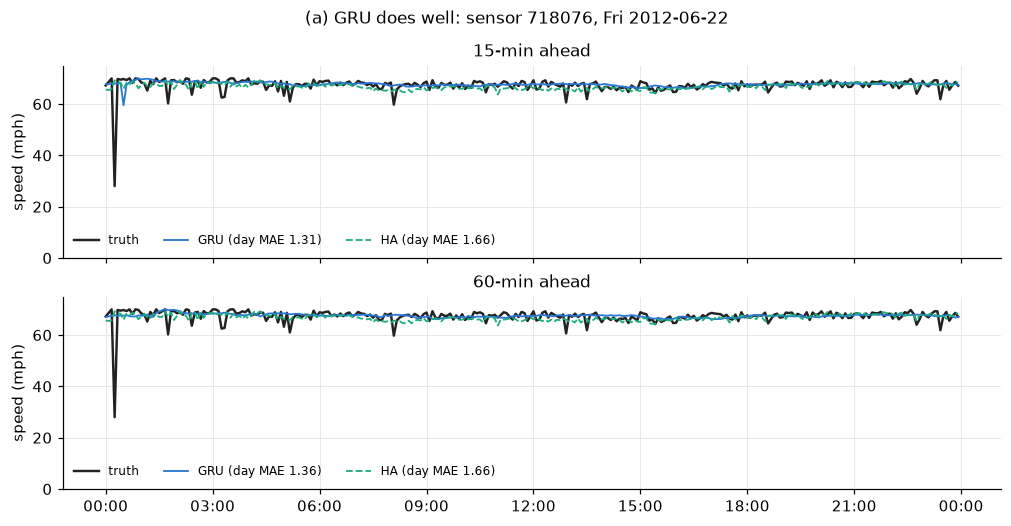

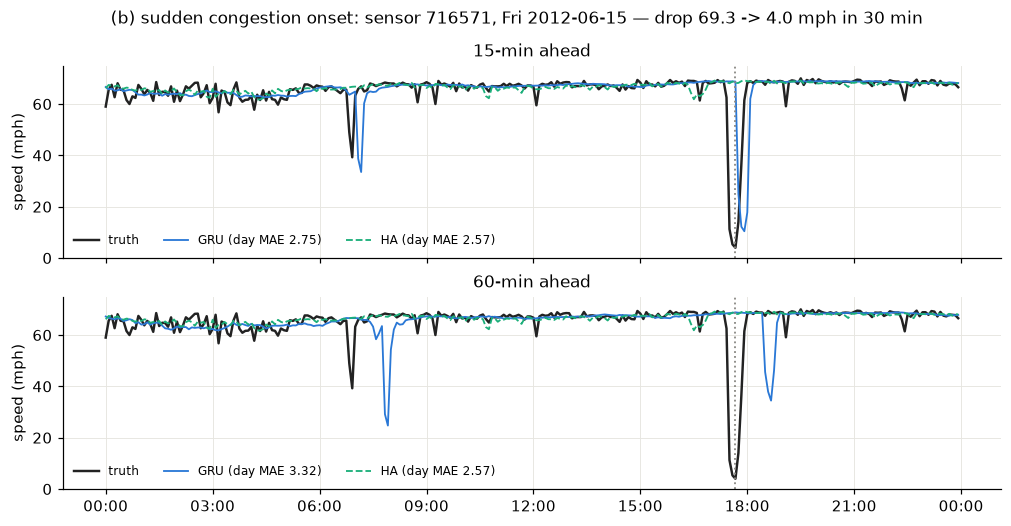

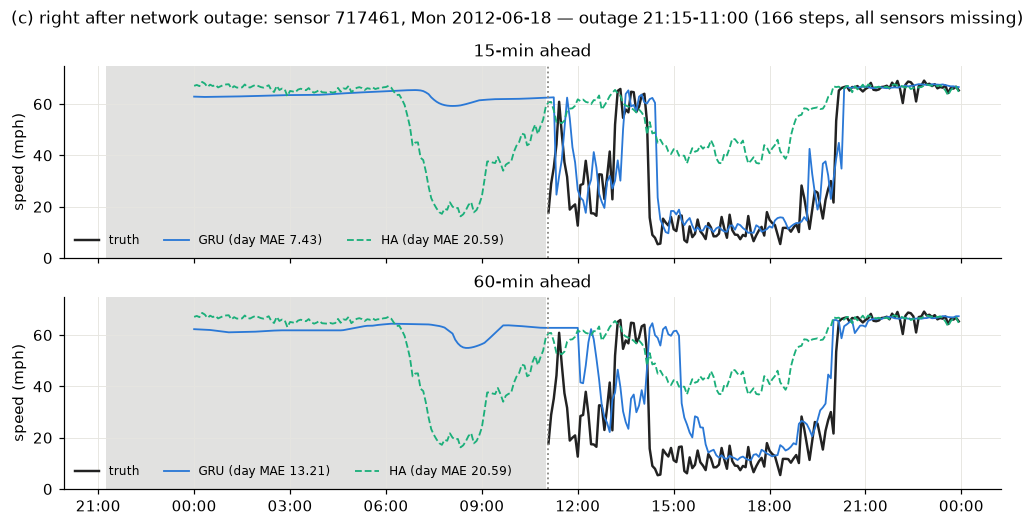

,case,sensor_id,date,event_time,note,GRU MAE 15min,HA MAE 15min,GRU MAE 60min,HA MAE 60min
0,(a) GRU does well,718076,2012-06-22 (Fri),,,1.31,1.66,1.36,1.66
1,(b) sudden congestion onset,716571,2012-06-15 (Fri),2012-06-15 17:40,drop 69.3 -> 4.0 mph in 30 min,2.75,2.57,3.32,2.57
2,(c) right after network outage,717461,2012-06-18 (Mon),2012-06-18 11:05,"outage 21:15-11:00 (166 steps, all sensors mis...",7.43,20.59,13.21,20.59


In [19]:
T = len(TS)
def series(k, h):
    out = np.full((T, y.shape[2]), np.nan, np.float32)
    out[TGT[:, h - 1]] = PRED[k][:, h - 1]
    return out
S = {(k, h): series(k, h) for k in MODELS for h in (3, 12)}
TRUTH = np.where(RAW > 0, RAW, np.nan).astype(np.float32)
DAY = TS.normalize()
covered = ~np.isnan(S[("GRU", 12)][:, 0])
days = [d for d in DAY[s_te:e_te].unique() if d.dayofweek < 5 and covered[DAY == d].all() and (DAY == d).sum() == 288]
print(f"{len(days)} full test weekdays: {days[0].date()} .. {days[-1].date()}")

def day_idx(d):
    return np.where(DAY == d)[0]

# (a) lowest GRU-60 day MAE among congested, well-observed sensor-days
best = (np.inf, None, None)
for d in days:
    ix = day_idx(d)
    tr, pr = TRUTH[ix], S[("GRU", 12)][ix]
    ok = (np.isfinite(tr).mean(0) >= 0.95) & (np.nanmin(np.where(np.isfinite(tr), tr, 99), 0) < 40)
    m = np.nanmean(np.abs(pr - tr), 0)
    m[~ok] = np.inf
    n = int(np.argmin(m))
    if m[n] < best[0]:
        best = (float(m[n]), d, n)
case_a = {"case": "(a) GRU does well", "sensor_idx": best[2], "day": best[1], "t": None}

# (b) largest 30-min drop on a full weekday
drop = np.full_like(TRUTH, np.nan); drop[6:] = TRUTH[:-6] - TRUTH[6:]
valid = np.zeros(T, bool); valid[np.concatenate([day_idx(d) for d in days])] = True
dd = np.where(valid[:, None], drop, np.nan)
for t, n in zip(*np.unravel_index(np.argsort(np.nan_to_num(dd, nan=-1), axis=None)[::-1], dd.shape)):
    if np.isfinite(TRUTH[day_idx(DAY[t]), n]).mean() >= 0.9:
        break
case_b = {"case": "(b) sudden congestion onset", "sensor_idx": int(n), "day": DAY[t], "t": int(t),
          "note": f"drop {TRUTH[t - 6, n]:.1f} -> {TRUTH[t, n]:.1f} mph in 30 min"}

# (c) longest network-wide outage ending on a full test weekday
allzero = (RAW == 0).all(1)
runs, t0 = [], None
for t in range(s_te, e_te):
    if allzero[t] and t0 is None: t0 = t
    if not allzero[t] and t0 is not None: runs.append((t0, t - 1)); t0 = None
out_runs = pd.DataFrame([{"start": TS[a], "end": TS[b], "steps": b - a + 1, "a": a, "b": b} for a, b in runs])
print(f"network-wide outages in test: {len(out_runs)} runs, {out_runs.steps.sum()} steps total")
display(out_runs.sort_values("steps", ascending=False).head(5)[["start", "end", "steps"]])
cand = out_runs[out_runs.end.dt.normalize().isin(days)].sort_values("steps", ascending=False)
oa, ob = int(cand.iloc[0].a), int(cand.iloc[0].b)
after = np.arange(ob + 1, ob + 13)
e15 = np.abs(S[("GRU", 3)][after] - TRUTH[after])
e15[:, np.isfinite(TRUTH[after]).sum(0) < 10] = np.nan
n_c = int(np.nanargmax(np.nanmean(e15, 0)))
case_c = {"case": "(c) right after network outage", "sensor_idx": n_c, "day": DAY[ob], "t": ob + 1,
          "note": f"outage {TS[oa]:%H:%M}-{TS[ob]:%H:%M} ({ob - oa + 1} steps, all sensors missing)"}
NUM["outages_test"] = {"runs": len(out_runs), "steps": int(out_runs.steps.sum())}

def plot_case(c, fname):
    ix, n = day_idx(c["day"]), c["sensor_idx"]
    t_ax = TS[ix]
    fig, axs = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    row = {"case": c["case"], "sensor_id": SIDS[n], "date": f"{c['day']:%Y-%m-%d (%a)}",
           "event_time": "" if c["t"] is None else f"{TS[c['t']]:%Y-%m-%d %H:%M}", "note": c.get("note", "")}
    for ax, h in zip(axs, (3, 12)):
        tr = TRUTH[ix, n]
        ax.plot(t_ax, tr, color=COL["truth"], lw=1.6, label="truth")
        for k, ls in [("GRU", "-"), ("HA", "--")]:
            pr = S[(k, h)][ix, n]
            e = float(np.nanmean(np.abs(pr - tr)))
            row[f"{k} MAE {h * 5}min"] = round(e, 2)
            ax.plot(t_ax, pr, ls, color=COL[k], lw=1.2, label=f"{k} (day MAE {e:.2f})")
        if c["t"] is not None:
            ax.axvline(TS[c["t"]], color=GRAY, ls=":", lw=1.2)
        if c["case"].startswith("(c)"):
            ax.axvspan(TS[oa], TS[ob], color=GRAY, alpha=0.25, lw=0)
        ax.set(ylabel="speed (mph)", title=f"{h * 5}-min ahead", ylim=(0, 75))
        ax.legend(loc="lower left", fontsize=8, ncol=3)
    axs[1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    fig.suptitle(f"{c['case']}: sensor {SIDS[n]}, {c['day']:%a %Y-%m-%d}" + (f" — {c['note']}" if c.get("note") else ""), fontsize=11)
    save(fig, fname)
    return row

cases = pd.DataFrame([plot_case(case_a, "Q1_good_sensor"), plot_case(case_b, "Q2_congestion_onset"),
                      plot_case(case_c, "Q3_after_outage")])
cases.to_csv(FIG / "qualitative_cases.csv", index=False)
NUM["qualitative"] = cases.to_dict("records")
display(cases)

**Takeaways.**
* **(a)** Sensor 718076 (Fri 2012-06-22): the GRU tracks a congested day closely, with a day MAE of 1.31 / 1.36 mph at 15 / 60 min vs 1.66 for HA.
* **(b)** Sensor 716571 (Fri 2012-06-15, 69.3 → 4.0 mph by 17:40): the GRU reproduces the crash **one horizon late**, 15 min later at h = 3 and about 60 min later at h = 12, when the real congestion has already cleared. Its day MAE (2.75 / 3.32) is worse than HA's (2.57), which just predicts free flow.
* **(c)** Sensor 717461 (Mon 2012-06-18), right after a 166-step network-wide outage that ends at 11:00: the GRU re-locks onto the day's unusual all-afternoon congestion once inputs return (day MAE 7.43 / 13.21). HA, blind to the current state, scores 20.59. The first predictions after the outage come from mean-filled, all-masked inputs and sit near free-flow speed.

## 4. Failure analysis
### 4.1 MAE by time of day, weekday vs weekend

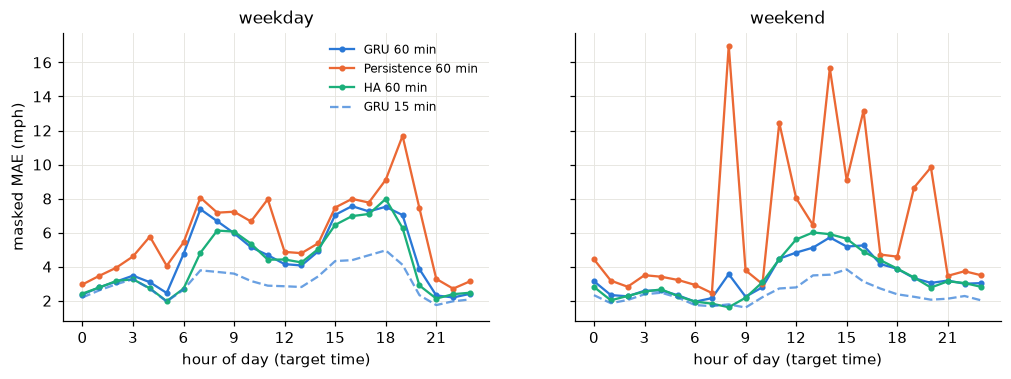

GRU 60-min weekday: peak 7.56 mph at 16:00, night (0-4h) 2.97, AM 7-9h 6.67, PM 15-18h 7.34; weekend peak 5.72 at 14:00, weekend mean 3.42 vs weekday mean 4.67
weekday hours where GRU-60 is worse than HA: [1, 3, 4, 5, 6, 7, 8, 11, 15, 16, 17, 19, 20, 21]


In [20]:
hour = TS.hour.to_numpy()[TGT]                    # (W, 12) hour of the target time
wkend = (TS.dayofweek.to_numpy() >= 5)[TGT]
rows = []
for h in (3, 12):
    o = OBS[:, h - 1]
    for k in MODELS:
        e = np.where(o, ERR[k][:, h - 1], 0).sum(1); c = o.sum(1)
        g = pd.DataFrame({"hour": hour[:, h - 1], "weekend": wkend[:, h - 1], "e": e, "c": c}).groupby(["weekend", "hour"]).sum()
        for (we, hr), r in g.iterrows():
            rows.append({"horizon": h * 5, "model": k, "weekend": we, "hour": hr, "MAE": r.e / r.c})
tod = pd.DataFrame(rows)
tod.to_csv(FIG / "mae_by_tod.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, we in zip(axs, (False, True)):
    for k in MODELS:
        d = tod[(tod.horizon == 60) & (tod.model == k) & (tod.weekend == we)]
        ax.plot(d.hour, d.MAE, "o-", ms=3, color=COL[k], label=f"{k} 60 min")
    d = tod[(tod.horizon == 15) & (tod.model == "GRU") & (tod.weekend == we)]
    ax.plot(d.hour, d.MAE, "--", color=C1, alpha=0.7, label="GRU 15 min")
    ax.set(xlabel="hour of day (target time)", title="weekend" if we else "weekday", xticks=range(0, 24, 3))
axs[0].set_ylabel("masked MAE (mph)"); axs[0].legend(fontsize=8)
save(fig, "FA1_mae_by_tod")
g = tod[(tod.model == "GRU") & (tod.horizon == 60)]
wd, we_ = g[~g.weekend].set_index("hour").MAE, g[g.weekend].set_index("hour").MAE
night = wd.loc[0:4].mean()
NUM["tod"] = {"wd_peak_hour": int(wd.idxmax()), "wd_peak_mae": round(wd.max(), 2), "wd_night_mae_0_4": round(night, 2),
              "wd_am_7_9": round(wd.loc[7:9].mean(), 2), "wd_pm_15_18": round(wd.loc[15:18].mean(), 2),
              "we_peak_hour": int(we_.idxmax()), "we_peak_mae": round(we_.max(), 2), "we_mean": round(we_.mean(), 2),
              "wd_mean": round(wd.mean(), 2)}
print(f"GRU 60-min weekday: peak {wd.max():.2f} mph at {wd.idxmax()}:00, night (0-4h) {night:.2f}, "
      f"AM 7-9h {wd.loc[7:9].mean():.2f}, PM 15-18h {wd.loc[15:18].mean():.2f}; weekend peak {we_.max():.2f} at {we_.idxmax()}:00, "
      f"weekend mean {we_.mean():.2f} vs weekday mean {wd.mean():.2f}")
ha_wd = tod[(tod.model == "HA") & (tod.horizon == 60) & (~tod.weekend)].set_index("hour").MAE
worse_than_ha = wd[wd > ha_wd].index.tolist()
NUM["tod"]["gru60_worse_than_ha_hours_weekday"] = worse_than_ha
print(f"weekday hours where GRU-60 is worse than HA: {worse_than_ha}")

**Takeaway.** On weekdays the GRU-60 error peaks at **7.56 mph at 16:00** vs 2.97 overnight (0–4 h). The AM peak (7–9 h) averages 6.67 and the PM peak (15–18 h) 7.34. On weekends the error is lower and flatter (mean 3.42 vs 4.67 on weekdays). GRU-60 is worse than HA in 14 of 24 weekday hours, including the rush-hour onset hours 7–8 and 15–17 h. In other words, it loses exactly where recurring congestion starts, which HA knows from the calendar. The large persistence spikes on weekends come from the long weekend outages (all-missing inputs make persistence predict 0).

### 4.2 Lag around sharp drops
**Event:** observed truth falls by more than 15 mph within 30 min (6 steps) at time *t₀* (both endpoints observed). Events at the same sensor are de-duplicated 1 h apart.

*Note:* events are selected by a high value at t₀ − 30 min and a low value at t₀. The averaged truth therefore shows a spike at −30 min and a dip at 0 that partly come from that selection (regression to the mean). The predictions inherit the spike, shifted by their horizon.

**Lag:** we use the midpoint level *m* = (mean truth over [t₀−60, t₀−35 min] + min truth over [t₀, t₀+60 min]) / 2. The lag is the number of 5-min steps between the first time the **prediction** falls below *m* and the first time the **truth** does (searching from t₀−30 min to t₀+2 h). A prediction that never crosses within that range counts as "never".

9,974 sharp-drop events at 207 sensors


,model,horizon (min),events,never crosses,median lag (steps),IQR,"MAE in [t0, t0+60]"
0,GRU,15,9974,0.25,3.0,3–4,9.57
1,GRU,60,9974,0.40,12.0,9–13,15.99
2,Persistence,15,9974,0.02,3.0,3–3,10.00
3,Persistence,60,9974,0.02,12.0,0–12,16.77
4,HA,any,9974,0.57,2.0,-2–9,11.73


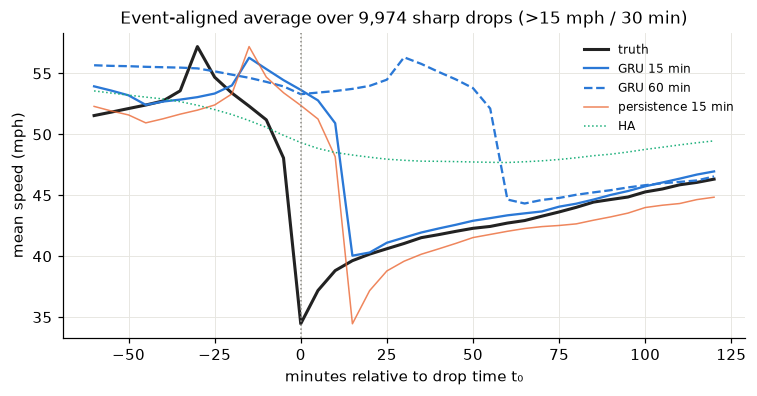

GRU-15 median lag 3 steps (15 min), GRU-60 median lag 12 steps (60 min); GRU-60 never reaches the midpoint in 40% of events


In [21]:
OFF = np.arange(-12, 25)
cand = (drop > 15) & np.isfinite(drop)
lo, hi = s_te + 23 + 12, e_te - 25            # every offset has a 60-min-ahead prediction
ev = []
for n in range(y.shape[2]):
    last = -10**9
    for t in np.where(cand[lo:hi, n])[0] + lo:
        if t - last >= 12:
            ev.append((t, n)); last = t
ev = np.array(ev)
print(f"{len(ev):,} sharp-drop events at {len(np.unique(ev[:, 1]))} sensors")
tt = ev[:, :1] + OFF[None]                                # (E, len(OFF))
A = {"truth": TRUTH[tt, ev[:, 1:2]]}
for k in MODELS:
    for h in (3, 12):
        A[(k, h)] = S[(k, h)][tt, ev[:, 1:2]]
pre = np.nanmean(A["truth"][:, (OFF >= -12) & (OFF <= -7)], 1)
post = np.nanmin(A["truth"][:, (OFF >= 0) & (OFF <= 12)], 1)
mid = (pre + post) / 2
search = OFF >= -6
def first_cross(a):
    below = (a < mid[:, None]) & search[None]
    return np.where(below.any(1), OFF[np.argmax(below, 1)], np.nan)
c_true = first_cross(A["truth"])
lag_rows = []
LAG = {}
for k, h in [("GRU", 3), ("GRU", 12), ("Persistence", 3), ("Persistence", 12), ("HA", 3)]:
    lag = first_cross(A[(k, h)]) - c_true
    LAG[(k, h)] = lag
    ok = np.isfinite(lag)
    lag_rows.append({"model": k, "horizon (min)": h * 5 if k != "HA" else "any", "events": len(lag),
                     "never crosses": 1 - ok.mean(), "median lag (steps)": np.median(lag[ok]),
                     "IQR": f"{np.percentile(lag[ok], 25):.0f}–{np.percentile(lag[ok], 75):.0f}",
                     "MAE in [t0, t0+60]": float(np.nanmean(np.abs(A[(k, h)] - A['truth'])[:, (OFF >= 0) & (OFF <= 12)]))})
lagtab = pd.DataFrame(lag_rows)
display(lagtab.round(2))
lagtab.round(2).to_csv(FIG / "drop_lag.csv", index=False)
NUM["drop_lag"] = {"events": int(len(ev)), "sensors": int(len(np.unique(ev[:, 1]))), "table": lagtab.round(2).to_dict("records")}

fig, ax = plt.subplots(figsize=(8, 3.6))
xm = OFF * 5
ax.plot(xm, np.nanmean(A["truth"], 0), color=COL["truth"], lw=2, label="truth")
ax.plot(xm, np.nanmean(A[("GRU", 3)], 0), color=C1, label="GRU 15 min")
ax.plot(xm, np.nanmean(A[("GRU", 12)], 0), color=C1, ls="--", label="GRU 60 min")
ax.plot(xm, np.nanmean(A[("Persistence", 3)], 0), color=C2, lw=1, alpha=0.8, label="persistence 15 min")
ax.plot(xm, np.nanmean(A[("HA", 3)], 0), color=C3, lw=1, ls=":", label="HA")
ax.axvline(0, color=GRAY, ls=":", lw=1)
ax.set(xlabel="minutes relative to drop time t₀", ylabel="mean speed (mph)", title=f"Event-aligned average over {len(ev):,} sharp drops (>15 mph / 30 min)")
ax.legend(fontsize=8)
save(fig, "FA2_drop_lag")
g15, g60 = LAG[("GRU", 3)], LAG[("GRU", 12)]
print(f"GRU-15 median lag {np.nanmedian(g15):.0f} steps ({5 * np.nanmedian(g15):.0f} min), GRU-60 median lag "
      f"{np.nanmedian(g60):.0f} steps ({5 * np.nanmedian(g60):.0f} min); GRU-60 never reaches the midpoint in "
      f"{np.isnan(g60).mean():.0%} of events")

**Takeaway.** Over 9,974 sharp drops, the GRU's median lag equals its horizon. At 15 min it is **3 steps (IQR 3–4)** and at 60 min **12 steps (IQR 9–13)**, the same medians as persistence (3 and 12). The GRU-60 prediction never reaches the drop midpoint in **40%** of events. So at onsets the model is reacting to the drop once it reaches its own inputs, not anticipating it. During the hour after t₀, GRU-60 MAE is 15.99 mph, close to persistence (16.77) and worse than HA (11.73).

### 4.3 MAE vs missing values in the input window
Missing fraction of the 12 input steps of the *same sensor* (the mask channel tells the GRU which ones were filled with the train mean).

,missing input steps,horizon (min),share of targets,GRU,Persistence,HA
0,0,15,0.943,2.944,3.455,4.154
1,0,60,0.926,4.376,5.313,4.153
2,1–3,15,0.028,3.288,3.804,4.679
3,1–3,60,0.031,4.418,5.278,4.461
4,4–6,15,0.011,3.573,3.929,5.542
5,4–6,60,0.014,5.561,6.323,5.416
6,7–11,15,0.013,3.793,4.195,4.658
7,7–11,60,0.015,5.302,6.210,4.812
8,12 (all),15,0.004,8.287,59.135,4.563
9,12 (all),60,0.015,8.275,59.537,4.382


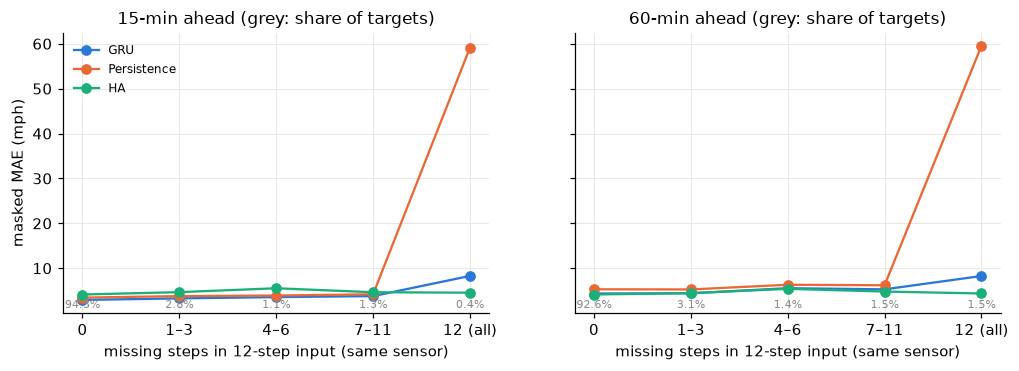

GRU-15 MAE: 0 missing 2.94 -> all missing 8.29 mph (HA 4.56); GRU-60: 4.38 -> 8.27 (HA 4.38)


In [22]:
kmiss = np.rint(XMISS * 12).astype(int)                     # (W, N) missing input steps
bins = [(0, 0, "0"), (1, 3, "1–3"), (4, 6, "4–6"), (7, 11, "7–11"), (12, 12, "12 (all)")]
rows = []
for lo_, hi_, lab in bins:
    b = (kmiss >= lo_) & (kmiss <= hi_)
    for h in (3, 12):
        sel = np.zeros_like(OBS); sel[:, h - 1] = b; sel &= OBS
        rows.append({"missing input steps": lab, "horizon (min)": h * 5, "share of targets": sel.sum() / OBS[:, h - 1].sum(),
                     **{k: mae(k, sel) for k in MODELS}})
miss = pd.DataFrame(rows)
display(miss.round(3))
miss.round(3).to_csv(FIG / "mae_vs_missing.csv", index=False)
NUM["missing"] = miss.round(2).to_dict("records")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.3), sharey=True)
for ax, h in zip(axs, (15, 60)):
    d = miss[miss["horizon (min)"] == h].set_index("missing input steps")
    for k in MODELS:
        ax.plot(d.index, d[k], "o-", color=COL[k], label=k)
    for i, (lab, r) in enumerate(d.iterrows()):
        ax.annotate(f"{r['share of targets']:.1%}", (i, ax.get_ylim()[0]), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color=GRAY)
    ax.set(xlabel="missing steps in 12-step input (same sensor)", title=f"{h}-min ahead (grey: share of targets)")
axs[0].set_ylabel("masked MAE (mph)"); axs[0].legend(fontsize=8)
save(fig, "FA3_mae_vs_missing")
m60 = miss[miss["horizon (min)"] == 60].set_index("missing input steps")
m15 = miss[miss["horizon (min)"] == 15].set_index("missing input steps")
print(f"GRU-15 MAE: 0 missing {m15.loc['0', 'GRU']:.2f} -> all missing {m15.loc['12 (all)', 'GRU']:.2f} mph "
      f"(HA {m15.loc['12 (all)', 'HA']:.2f}); GRU-60: {m60.loc['0', 'GRU']:.2f} -> {m60.loc['12 (all)', 'GRU']:.2f} (HA {m60.loc['12 (all)', 'HA']:.2f})")

**Takeaway.** 94.3% of 15-min targets have a complete input window, where the GRU MAE is 2.94. Partial gaps cost little (3.29–3.79 at 15 min). When **all 12 input steps are missing** (0.4% / 1.5% of 15 / 60-min targets), the GRU falls to **8.29 / 8.27 mph vs 4.56 / 4.38 for HA**. Mean-fill plus the mask tells it *that* data is missing, but it has nothing to forecast from.

### 4.4 Per-sensor MAE and the spatial signal
The per-sensor masked MAE is computed over all test windows. We then check the **neighbour evidence** for the 10 worst sensors (GRU 60-min):
* **Large-error events** are the onset of a run where the GRU-60 prediction is at least 15 mph *above* the truth (missed congestion), de-duplicated 1 h apart.
* For each event, the target's own **drop time** τᵢ is the first step in [t₀ − 2 h, t₀ + 30 min] where its speed fell by more than 10 mph within 30 min. Events with no such drop are skipped.
* A sensor j "dropped earlier" if it had a drop of the same kind (> 10 mph within 30 min) ending in the **30 min before τᵢ**, i.e. in [τᵢ − 30 min, τᵢ).
* Neighbours are split by DCRNN edge direction (`adj[i, j]` = edge i→j). **into i** means adj[j, i] > 0.1; **out of i** means adj[i, j] > 0.1.
* **Control:** non-neighbour sensors (all of them, and a size-matched random draw, seed 6600). Rush hour makes many sensors drop at similar times, so a neighbour only carries information if it drops earlier *more often than an arbitrary sensor does*.

,sensor_id,GRU 60,GRU 15,HA,Persistence 60,test missing rate,mean speed,share <40 mph,in-degree,out-degree
rank,,,,,,,,,,
1,717462,10.08,5.09,11.75,11.16,0.10,47.500000,0.40,14,13
2,718045,9.91,5.77,7.52,11.19,0.14,48.330002,0.30,6,14
3,717461,9.81,4.94,10.01,10.53,0.20,43.360001,0.48,17,11
4,717458,9.68,4.96,9.04,10.03,0.10,40.630001,0.50,13,15
5,773939,9.53,5.39,9.91,11.47,0.10,50.810001,0.25,3,3
6,717466,9.15,5.11,11.95,10.90,0.10,49.959999,0.32,14,11
7,717468,9.14,4.72,12.76,10.69,0.10,48.869999,0.28,14,14
8,716339,9.02,4.05,7.13,8.78,0.10,37.450001,0.56,15,13
9,717472,8.65,4.45,12.36,10.53,0.13,53.720001,0.25,10,12


Spearman corr of per-sensor GRU-60 MAE with: {'share <40 mph': 0.89, 'test missing rate': 0.13, 'mean speed': -0.81}
worst 10 sensors (4.8% of sensors) carry 10.1% of GRU-60 absolute error


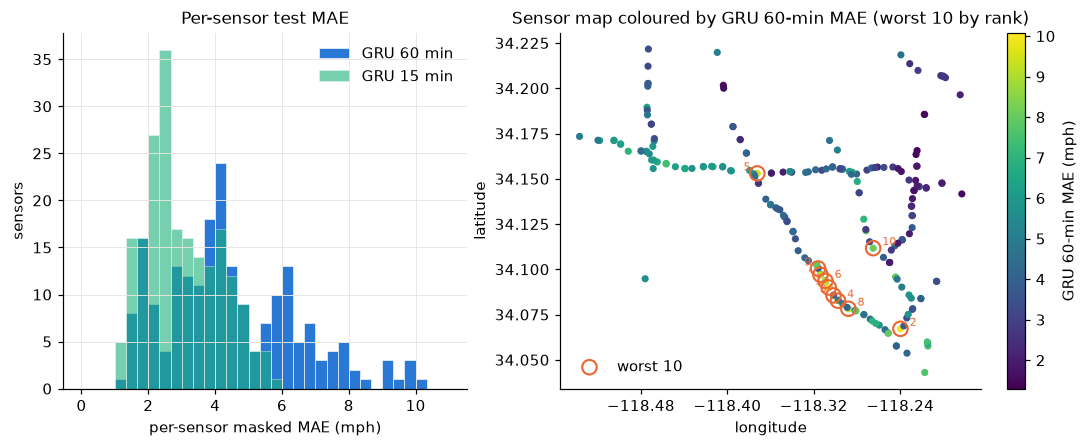

In [23]:
smae = {k: {h: np.where(OBS[:, h - 1], ERR[k][:, h - 1], 0).sum(0) / OBS[:, h - 1].sum(0) for h in (3, 12)} for k in MODELS}
miss_rate = (RAW[s_te:e_te] == 0).mean(0)
mean_spd = np.nanmean(TRUTH[s_te:e_te], 0)
cong_share = np.nanmean(np.where(np.isfinite(TRUTH[s_te:e_te]), TRUTH[s_te:e_te] < 40, np.nan), 0)
sens = pd.DataFrame({"sensor_id": SIDS, "GRU 60": smae["GRU"][12], "GRU 15": smae["GRU"][3], "HA": smae["HA"][12],
                     "Persistence 60": smae["Persistence"][12], "test missing rate": miss_rate,
                     "mean speed": mean_spd, "share <40 mph": cong_share,
                     "in-degree": (ADJ > 0.1).sum(0) - 1, "out-degree": (ADJ > 0.1).sum(1) - 1})
sens.round(3).to_csv(FIG / "per_sensor_mae.csv", index=False)
worst = sens.sort_values("GRU 60", ascending=False).head(10)
display(worst.round(2).assign(rank=range(1, 11)).set_index("rank"))
rho = sens[["GRU 60", "share <40 mph", "test missing rate", "mean speed"]].corr(method="spearman")["GRU 60"]
print("Spearman corr of per-sensor GRU-60 MAE with:", rho.drop("GRU 60").round(2).to_dict())
NUM["per_sensor"] = {"median": round(float(np.median(sens["GRU 60"])), 2), "p90": round(float(np.percentile(sens["GRU 60"], 90)), 2),
                     "max": round(float(sens["GRU 60"].max()), 2), "min": round(float(sens["GRU 60"].min()), 2),
                     "worst10": worst[["sensor_id", "GRU 60", "HA", "share <40 mph", "test missing rate"]].round(2).to_dict("records"),
                     "spearman": rho.drop("GRU 60").round(2).to_dict(),
                     "worst10_share_of_total_abs_err": None}
tot_err = np.where(OBS[:, 11], ERR["GRU"][:, 11], 0).sum(0)
NUM["per_sensor"]["worst10_share_of_total_abs_err"] = round(float(tot_err[worst.index].sum() / tot_err.sum()), 3)
print(f"worst 10 sensors ({10 / len(SIDS):.1%} of sensors) carry {tot_err[worst.index].sum() / tot_err.sum():.1%} of GRU-60 absolute error")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
hb = np.linspace(0, np.ceil(sens["GRU 60"].max()), 34)
axs[0].hist(sens["GRU 60"], bins=hb, color=C1, edgecolor="white", linewidth=0.4, label="GRU 60 min")
axs[0].hist(sens["GRU 15"], bins=hb, color=C3, alpha=0.6, edgecolor="white", linewidth=0.4, label="GRU 15 min")
axs[0].set(xlabel="per-sensor masked MAE (mph)", ylabel="sensors", title="Per-sensor test MAE"); axs[0].legend()
loc = LOC.reindex(SIDS)
sc = axs[1].scatter(loc.longitude, loc.latitude, c=sens["GRU 60"], cmap="viridis", s=22, edgecolor="none")
w = loc.loc[worst.sensor_id]
axs[1].scatter(w.longitude, w.latitude, s=90, facecolor="none", edgecolor=C2, lw=1.4, label="worst 10")
for rank, (sid, r) in enumerate(w.iterrows(), 1):
    axs[1].annotate(str(rank), (r.longitude, r.latitude), xytext=(-9 if rank % 2 else 6, 2), textcoords="offset points", fontsize=7, color=C2)
axs[1].xaxis.set_major_locator(plt.MaxNLocator(5))
plt.colorbar(sc, ax=axs[1], label="GRU 60-min MAE (mph)")
axs[1].set(xlabel="longitude", ylabel="latitude", title="Sensor map coloured by GRU 60-min MAE (worst 10 by rank)"); axs[1].legend(loc="lower left")
axs[1].grid(False)
save(fig, "FA4_sensor_mae")

,events,into: share earlier,out: share earlier,non-nbr: share earlier,any nbr earlier,any random (matched) earlier
sensor_id,,,,,,
717462,95,0.08,0.31,0.14,0.93,0.84
718045,85,0.12,0.17,0.12,0.87,0.72
717461,97,0.11,0.30,0.12,0.90,0.84
717458,106,0.10,0.27,0.11,0.94,0.83
773939,90,0.17,0.30,0.16,0.78,0.54
717466,106,0.10,0.32,0.16,0.96,0.90
717468,83,0.09,0.31,0.15,0.98,0.88
716339,68,0.13,0.27,0.10,0.94,0.79
717472,76,0.10,0.36,0.16,0.95,0.91


892 large-error drop events at the worst 10 sensors with a detectable own drop. In the 30 min before the target's drop, 12% of into-i neighbours and 27% of out-of-i neighbours had already dropped vs 14% of non-neighbours (0.8x / 1.9x). >=1 neighbour dropped first in 89% of events vs 81% for a size-matched random set


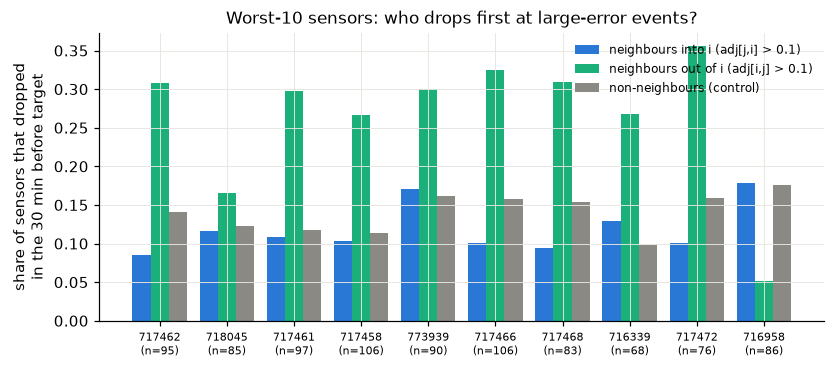

In [24]:
d10 = np.full_like(TRUTH, np.nan); d10[6:] = TRUTH[:-6] - TRUTH[6:]
DROP10 = np.nan_to_num(d10, nan=0) > 10
rng = np.random.default_rng(6600)
G60 = S[("GRU", 12)]
nb_rows = []
for i in worst.index:
    over = (G60[:, i] - TRUTH[:, i]) > 15
    over[:s_te + 23] = False
    events, last = [], -10**9
    for t in np.where(over)[0]:
        if t - last >= 12 and not over[t - 1]:
            events.append(t); last = t
    into = [j for j in np.where(ADJ[:, i] > 0.1)[0] if j != i]
    outo = [j for j in np.where(ADJ[i, :] > 0.1)[0] if j != i]
    nbrs = set(into) | set(outo)
    pool = np.array([j for j in range(len(SIDS)) if j not in nbrs and j != i])
    for t0 in events:
        own = np.where(DROP10[max(t0 - 24, 0):t0 + 7, i])[0]
        if len(own) == 0:
            continue
        tau = max(t0 - 24, 0) + own[0]
        early = DROP10[tau - 6:tau].any(0)                     # (N,) dropped in the 30 min before tau
        ctrl = rng.choice(pool, size=min(len(nbrs), len(pool)), replace=False)
        nb_rows.append({"sensor_id": SIDS[i], "t0": TS[t0], "tau": TS[tau], "n_into": len(into), "n_out": len(outo),
                        "into: share earlier": early[into].mean() if into else np.nan,
                        "out: share earlier": early[outo].mean() if outo else np.nan,
                        "non-nbr: share earlier": early[pool].mean(),
                        "any nbr earlier": early[list(nbrs)].any() if nbrs else np.nan,
                        "any random (matched) earlier": early[ctrl].any()})
nb = pd.DataFrame(nb_rows)
nb.to_csv(FIG / "worst_sensor_neighbor_events.csv", index=False)
cols = ["into: share earlier", "out: share earlier", "non-nbr: share earlier", "any nbr earlier", "any random (matched) earlier"]
nb[cols] = nb[cols].astype(float)
summary_nb = nb.groupby("sensor_id")[cols].mean()
summary_nb.insert(0, "events", nb.groupby("sensor_id").size())
summary_nb = summary_nb.reindex(worst.sensor_id).dropna(how="all")
display(summary_nb.round(2))
tot = nb[cols].mean()
ratio_in = tot["into: share earlier"] / tot["non-nbr: share earlier"]
ratio_out = tot["out: share earlier"] / tot["non-nbr: share earlier"]
print(f"{len(nb)} large-error drop events at the worst {nb.sensor_id.nunique()} sensors with a detectable own drop. "
      f"In the 30 min before the target's drop, {tot['into: share earlier']:.0%} of into-i neighbours and "
      f"{tot['out: share earlier']:.0%} of out-of-i neighbours had already dropped vs {tot['non-nbr: share earlier']:.0%} of "
      f"non-neighbours ({ratio_in:.1f}x / {ratio_out:.1f}x). >=1 neighbour dropped first in {tot['any nbr earlier']:.0%} of events "
      f"vs {tot['any random (matched) earlier']:.0%} for a size-matched random set")
NUM["neighbors"] = {"events": int(len(nb)), "sensors": int(nb.sensor_id.nunique()), **{k: round(float(v), 3) for k, v in tot.items()},
                    "ratio_into_vs_nonnbr": round(float(ratio_in), 2), "ratio_out_vs_nonnbr": round(float(ratio_out), 2)}

fig, ax = plt.subplots(figsize=(8.5, 3.4))
xs = np.arange(len(summary_nb))
for o, (c, col, lab) in enumerate([("into: share earlier", C1, "neighbours into i (adj[j,i] > 0.1)"),
                                   ("out: share earlier", C3, "neighbours out of i (adj[i,j] > 0.1)"),
                                   ("non-nbr: share earlier", GRAY, "non-neighbours (control)")]):
    ax.bar(xs + (o - 1) * 0.27, summary_nb[c], 0.27, color=col, label=lab)
ax.set(xticks=xs, xticklabels=[f"{s}\n(n={int(e)})" for s, e in zip(summary_nb.index, summary_nb.events)],
       ylabel="share of sensors that dropped\nin the 30 min before target", title="Worst-10 sensors: who drops first at large-error events?")
ax.tick_params(axis="x", labelsize=7); ax.legend(fontsize=8)
save(fig, "FA4b_neighbor_lead")

**Takeaway.** Per-sensor GRU-60 MAE ranges from 1.30 to 10.08 mph (median 4.21, 90th percentile 7.03). It is driven by how often the sensor is congested (Spearman ρ = 0.89 with share < 40 mph, −0.81 with mean speed), not by missingness (ρ = 0.13). Seven of the worst 10 sensors sit next to each other on a single corridor (717458–717472 and 716339; map ranks 1, 3, 4, 6–9), so the errors are spatially clustered.

**Spatial evidence.** At the worst sensors' 892 large-error drop events, **27% of out-of-i neighbours (adj[i, j] > 0.1) had already dropped in the 30 min before the target, vs 14% of non-neighbours (1.9×)**. In-neighbours were no more informative than random sensors (12%, 0.8×). If DCRNN edges follow traffic flow, "out of i" means downstream, which fits congestion travelling backwards from downstream bottlenecks. Either way, the warning signal lives at specific graph neighbours that this per-sensor GRU never sees.

### 4.5 Failure patterns → CI3 next steps
| # | Failure pattern (evidence) | CI3 step |
|---|---|---|
| 1 | **Lag = horizon at congestion onset**: median lag 3 / 12 steps at 15 / 60 min, the same as persistence (§4.2, Q2). | Graph WaveNet with forward + backward diffusion over `adj_METR-LA.pkl`. Downstream neighbours drop first 1.9× more often than random (§4.4). |
| 2 | **Worse than persistence in congestion** at every horizon (14.46 vs 13.42 mph at 60 min, §2). | Report congested-regime MAE as a headline CI3 metric for graph vs no-graph. |
| 3 | **Worse than HA at 60 min** (4.46 vs 4.19), i.e. no sensor/calendar context. | Give both CI3 arms the same day-of-week input. Graph WaveNet's adaptive adjacency (learned node embeddings) adds sensor identity, and the no-graph arm gets the same embeddings, so the ablation isolates the graph. |
| 4 | **All-missing inputs** (8.27 vs HA 4.38 at 60 min, §4.3). | Spatial models can borrow observed neighbours. Re-run the §4.3 breakdown for the graph model. |
| 5 | **Errors cluster on one congested corridor** (worst 10 carry 10.1% of absolute error; ρ = 0.89 with congestion share). | Per-sensor MAE map for graph vs no-graph: gains should concentrate on this corridor if the graph helps. |

**CI3 protocol:** Graph WaveNet trained on this exact pipeline (same `DATA_DIR`, split, normalization, mask channel, masked-MAE loss, early stopping on val), with a **graph vs no-graph ablation** (real adjacency + adaptive vs identity adjacency, same budget). DCRNN is the fallback if Graph WaveNet is not stable in time.

## 5. Optional extras: seed variance and mask-channel ablation
The extra runs use the same config, changing only the seed (0 / 1 / 2, plus the main run's 42) or dropping the mask channel (`--no-mask`, seed 42). Each is evaluated on the same test windows by `src.evaluate` (`runs/<run>/test_metrics.json`). This cell is skipped if those runs are absent.

In [25]:
def load_run(name):
    r = RUNS_DIR / name
    if not (r / "test_metrics.json").exists():
        return None
    m = json.loads((r / "test_metrics.json").read_text()); sm = json.loads((r / "summary.json").read_text())
    return {"run": name, **{f"{h} MAE": m[h]["MAE"] for h in ["15 min", "30 min", "60 min"]},
            **{f"{h} RMSE": m[h]["RMSE"] for h in ["15 min", "30 min", "60 min"]},
            "best val MAE": sm["best_val_mae"], "epochs": sm["epochs_trained"], "best epoch": sm["best_epoch"], "min": sm["wall_clock_min"]}
seed_runs = [x for x in (load_run(n) for n in ["gru_h64", "gru_h64_seed0", "gru_h64_seed1", "gru_h64_seed2"]) if x]
nomask = load_run("gru_h64_nomask")
if len(seed_runs) > 1:
    sr = pd.DataFrame(seed_runs).set_index("run")
    display(sr.round(3))
    agg = sr.agg(["mean", "std"]).round(3)
    display(agg)
    NUM["seeds"] = {"n": len(sr), "runs": sr.round(3).reset_index().to_dict("records"), "mean": agg.loc["mean"].to_dict(), "std": agg.loc["std"].to_dict()}
    print("GRU test MAE over %d seeds (mean ± std): " % len(sr) + ", ".join(
        f"{h} {agg.loc['mean', f'{h} MAE']:.2f} ± {agg.loc['std', f'{h} MAE']:.2f}" for h in ["15 min", "30 min", "60 min"]))
if nomask:
    nm = pd.DataFrame([seed_runs[0], nomask]).set_index("run")
    display(nm.round(3))
    NUM["mask_ablation"] = nm.round(3).reset_index().to_dict("records")
    print("no-mask minus mask (seed 42), test MAE: " + ", ".join(
        f"{h} {nomask[f'{h} MAE'] - seed_runs[0][f'{h} MAE']:+.3f}" for h in ["15 min", "30 min", "60 min"]))
    # all-missing breakdown needs predictions; only summary metrics are stored for the extra runs

,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
run,,,,,,,,,,
gru_h64,2.994,3.599,4.465,5.892,7.276,8.948,3.249,40,40,18.217
gru_h64_seed0,2.996,3.603,4.471,5.903,7.292,8.962,3.254,40,40,19.642
gru_h64_seed1,2.996,3.605,4.484,5.897,7.272,8.943,3.258,40,39,18.468
gru_h64_seed2,3.000,3.608,4.472,5.903,7.282,8.936,3.255,40,40,18.012


,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
mean,2.996,3.604,4.473,5.899,7.280,8.947,3.254,40.0,39.75,18.585
std,0.002,0.003,0.008,0.005,0.009,0.011,0.004,0.0,0.50,0.729


GRU test MAE over 4 seeds (mean ± std): 15 min 3.00 ± 0.00, 30 min 3.60 ± 0.00, 60 min 4.47 ± 0.01


,15 min MAE,30 min MAE,60 min MAE,15 min RMSE,30 min RMSE,60 min RMSE,best val MAE,epochs,best epoch,min
run,,,,,,,,,,
gru_h64,2.994,3.599,4.465,5.892,7.276,8.948,3.249,40,40,18.217
gru_h64_nomask,3.016,3.629,4.498,5.975,7.360,9.018,3.266,40,40,18.235


no-mask minus mask (seed 42), test MAE: 15 min +0.021, 30 min +0.030, 60 min +0.033


In [26]:
(FIG / "ci2_numbers.json").write_text(json.dumps(NUM, indent=1, default=str))
print("wrote", FIG / "ci2_numbers.json")

wrote /Users/mikekwon/Documents/georgetownFall26/DSAN6600/Deep-Learning-6600/Project_check_in_2/figures/ci2_numbers.json
